# 01 – EDA : SEC 10-K Financial Reports   

In [20]:
from datasets import load_dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")

In [21]:
target_dir = '../data/samples'
# --- Charger ---
df = pd.read_parquet(target_dir + "/financial_reports_50000.parquet")
print(f"Shape: {df.shape}")

Shape: (50000, 19)


## 1. Overview   

In [22]:
print(f"Shape: {df.shape}")
print(f"Unique filings: {df['docID'].nunique()}")
print(f"Unique companies: {df['name'].nunique()}")
print(f"Date range: {df['filingDate'].min()} → {df['filingDate'].max()}")
print(f"\nDtypes:\n{df.dtypes}")     

Shape: (50000, 19)
Unique filings: 44
Unique companies: 2
Date range: 1994-08-24 → 2021-02-19

Dtypes:
cik                     object
sentence                object
section                  int64
labels                  object
filingDate              object
name                    object
docID                   object
sentenceID              object
sentenceCount            int64
tickers                 object
exchanges               object
entityType              object
sic                     object
stateOfIncorporation    object
tickerCount              int64
acceptanceDateTime      object
form                    object
reportDate              object
returns                 object
dtype: object


## 2. Labels & Returns   

label_30d
1    27778
0    22222
Name: count, dtype: int64
Positive (0): 44.4%
Negative (1): 55.6%


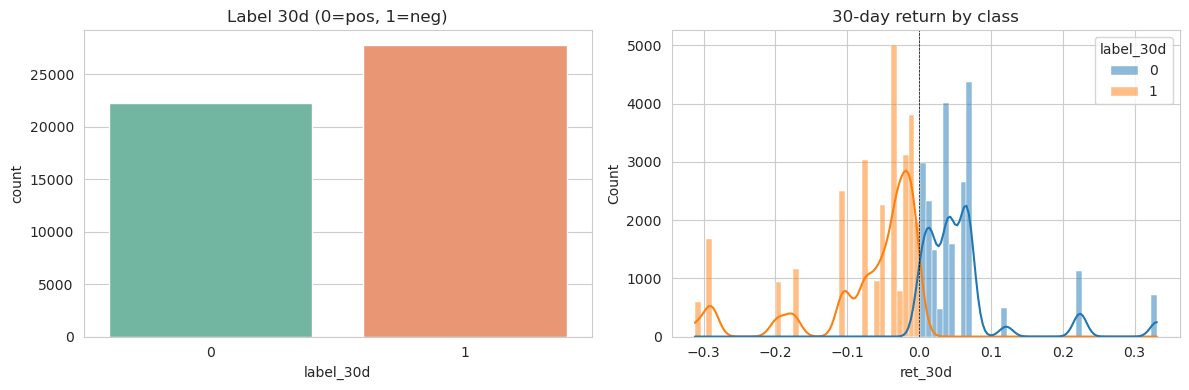

             count      mean       std      min       25%       50%       75%  \
label_30d                                                                       
0          22222.0  0.060075  0.068488  0.00198  0.017647  0.041123  0.066537   
1          27778.0 -0.072237  0.081959 -0.31221 -0.078300 -0.035735 -0.016553   

                max  
label_30d            
0          0.330935  
1         -0.002471  


In [23]:
# --- Extract labels (0=positive, 1=negative) ---
df["label_1d"]  = df["labels"].apply(lambda x: x["1d"])
df["label_5d"]  = df["labels"].apply(lambda x: x["5d"])
df["label_30d"] = df["labels"].apply(lambda x: x["30d"])

# --- Extract returns (float) ---
df["ret_1d"]  = df["returns"].apply(lambda x: x["1d"]["ret"])
df["ret_5d"]  = df["returns"].apply(lambda x: x["5d"]["ret"])
df["ret_30d"] = df["returns"].apply(lambda x: x["30d"]["ret"])

# --- Distribution (30d) ---
print(df["label_30d"].value_counts())
print(f"Positive (0): {(df['label_30d']==0).mean():.1%}")
print(f"Negative (1): {(df['label_30d']==1).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="label_30d", data=df, palette="Set2", ax=axes[0], hue="label_30d", legend=False)
axes[0].set_title("Label 30d (0=pos, 1=neg)")

sns.histplot(data=df, x="ret_30d", hue="label_30d", bins=80, kde=True, ax=axes[1])
axes[1].set_title("30-day return by class")
axes[1].axvline(0, color="k", ls="--", lw=0.5)
plt.tight_layout()
plt.show()

# --- Stats per class ---
print(df.groupby("label_30d")["ret_30d"].describe()) 

## 3. Temporal Consistency (1d/5d → 30d)     

In [24]:
ct = pd.crosstab(
    (df["label_1d"] == 1) & (df["label_5d"] == 1),
    df["label_30d"] == 1
)
ct.columns = ["30d=positive (0)", "30d=negative (1)"]
ct.index = ["1d & 5d negative", "otherwise"]
print(ct)   

                  30d=positive (0)  30d=negative (1)
1d & 5d negative             17109              9334
otherwise                     5113             18444


## 4. Filing Structure   

Sentences per filing: mean=1136, median=1150, min=124, max=1672


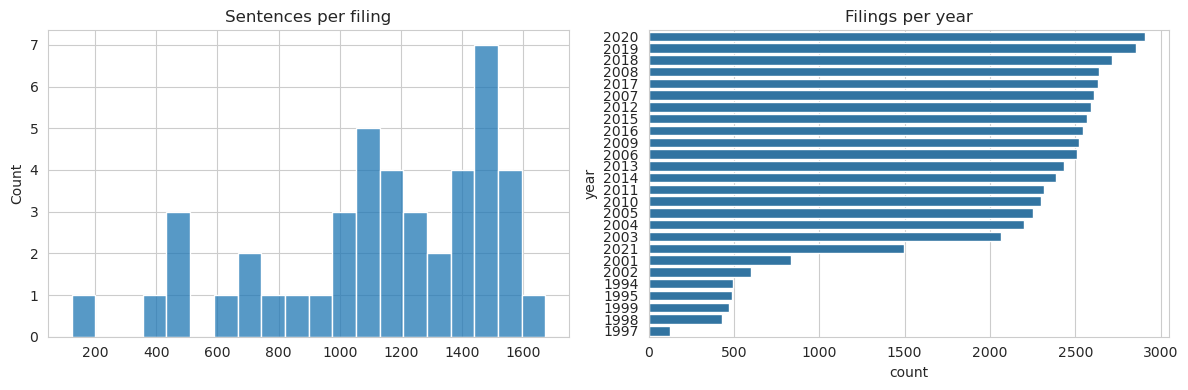

In [25]:
sent_per_filing = df.groupby("docID").size()
print(f"Sentences per filing: mean={sent_per_filing.mean():.0f}, "
      f"median={sent_per_filing.median():.0f}, "
      f"min={sent_per_filing.min()}, max={sent_per_filing.max()}")

df["year"] = df["filingDate"].str[:4]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sent_per_filing, bins=20, ax=axes[0])
axes[0].set_title("Sentences per filing")

sns.countplot(y="year", data=df, order=df["year"].value_counts().index, ax=axes[1])
axes[1].set_title("Filings per year")
plt.tight_layout()
plt.show()   

## 5. 10-K Sections     

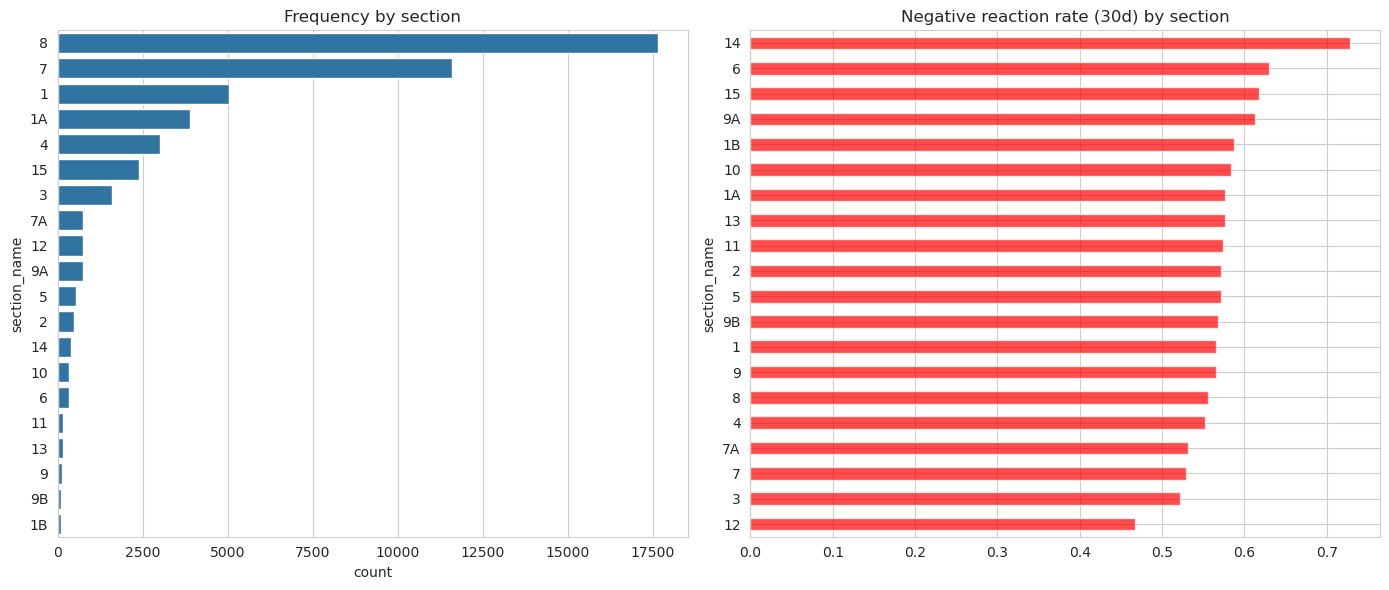

In [26]:
# section_name is already included in the firm-level sample
section_order = ["1", "1A", "1B", "2", "3", "4", "5", "6", "7", "7A",
                 "8", "9", "9A", "9B", "10", "11", "12", "13", "14", "15"]
df["section_name"] = df["sentenceID"].str.split("_").str[4]
df["section_name"] = pd.Categorical(df["section_name"], categories=section_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.countplot(y="section_name", data=df,
              order=df["section_name"].value_counts().index, ax=axes[0])
axes[0].set_title("Frequency by section")

neg_rate = df.groupby("section_name", observed=True)["label_30d"].mean().sort_values(ascending=True)
neg_rate.plot(kind="barh", ax=axes[1], color="red", alpha=0.7)
axes[1].set_title("Negative reaction rate (30d) by section")
plt.tight_layout()
plt.show()

## 6. Sentence Length     

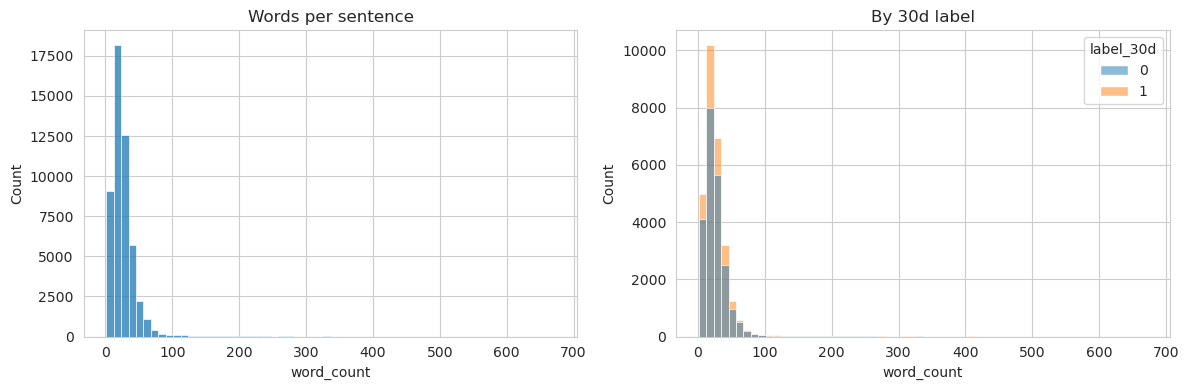

count    50000.000000
mean        25.744820
std         21.483035
min          1.000000
25%         15.000000
50%         22.000000
75%         32.000000
max        672.000000
Name: word_count, dtype: float64


In [27]:
df["word_count"] = df["sentence"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x="word_count", data=df, bins=60, ax=axes[0])
axes[0].set_title("Words per sentence")

sns.histplot(x="word_count", hue="label_30d", data=df, bins=60, ax=axes[1])
axes[1].set_title("By 30d label")
plt.tight_layout()
plt.show()

print(df["word_count"].describe())   

## 7. Discriminative N-grams   

In [28]:
eda_sample = df.sample(n=min(100_000, len(df)), random_state=42)
cv = CountVectorizer(ngram_range=(2,2), max_features=10000, stop_words="english")
cv.fit(eda_sample["sentence"])
features = cv.get_feature_names_out()

pos = cv.transform(eda_sample.loc[eda_sample["label_30d"]==0, "sentence"]).sum(axis=0).A1
neg = cv.transform(eda_sample.loc[eda_sample["label_30d"]==1, "sentence"]).sum(axis=0).A1

diff = pd.DataFrame({"pos": pos, "neg": neg, "ratio": neg/(pos+1)}, index=features)

print("=== Top bigrams → NÉGATIVE (1) ===")
print(diff.nlargest(15, "ratio")[["neg","pos","ratio"]])
print("\n=== Top bigrams → POSITIVE (0) ===")
print(diff.nsmallest(15, "ratio")[["pos","neg","ratio"]])   

=== Top bigrams → NÉGATIVE (1) ===
                     neg  pos      ratio
april 28              53    0  53.000000
fiscal 2016          157    2  52.333333
28 2017               52    0  52.000000
agreement foreign     44    0  44.000000
percent 2012          34    0  34.000000
fiscal 2015          256    7  32.000000
devices segment       30    0  30.000000
2020 abbott           29    0  29.000000
percent 2019          28    0  28.000000
1999 1998             27    0  27.000000
fiscal 2004           76    2  25.333333
agreement executive   25    0  25.000000
fiscal 2005           96    3  24.000000
march 13              22    0  22.000000
1993 1992             21    0  21.000000

=== Top bigrams → POSITIVE (0) ===
                        pos  neg  ratio
10 registrant            26    0    0.0
1995 1994                34    0    0.0
apb 14                   23    0    0.0
earnings june            17    0    0.0
fsp apb                  23    0    0.0
good service             20    0 

## 8. Position in Document     

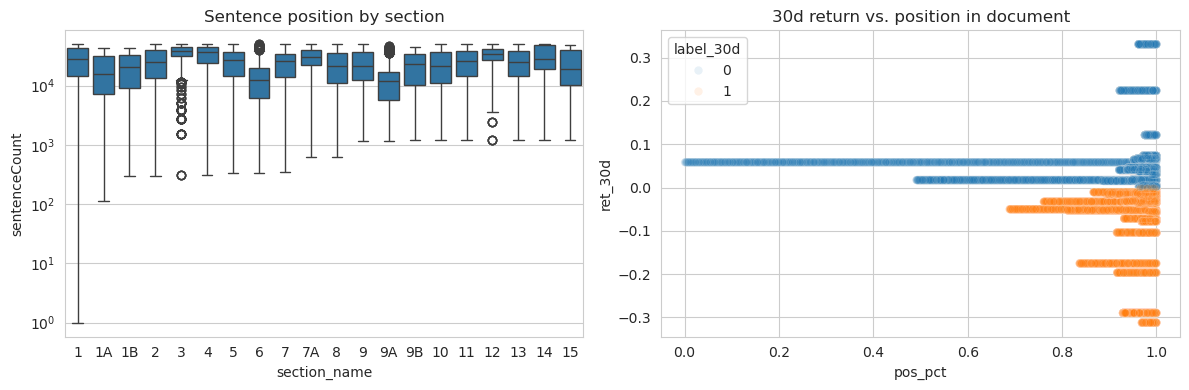

In [29]:
df["pos_pct"] = df["sentenceCount"] / df.groupby("docID")["sentenceCount"].transform("max")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="section_name", y="sentenceCount", data=df, ax=axes[0])
axes[0].set_title("Sentence position by section")
axes[0].set_yscale("log")

plot_sample = df.sample(n=min(50_000, len(df)), random_state=42)
sns.scatterplot(x="pos_pct", y="ret_30d", hue="label_30d", data=plot_sample, alpha=0.1, ax=axes[1])
axes[1].set_title("30d return vs. position in document")
plt.tight_layout()
plt.show()    

## 9. Sample Sentences      

In [30]:
np.random.seed(42)
print("=== NEGATIVE (1) ===")
for t in df.loc[df["label_30d"]==1, "sentence"].sample(5):
    print(f"  • {t[:120]}")

print("\n=== POSITIVE (0) ===")
for t in df.loc[df["label_30d"]==0, "sentence"].sample(5):
    print(f"  • {t[:120]}")   

=== NEGATIVE (1) ===
  • In certain of Abbott's businesses, primarily within diagnostics and medical optics, Abbott participates in selling arran
  • Elected Corporate Officer - 1996.
  • Diabetes Care product sales for the Diagnostic Products segment were favorably impacted by the acquisition of TheraSense
  • The fair value of long-term debt at December 31, 2013 and 2012 amounted to $3.9 billion and $19.6 billion, respectively 
  • We utilized a floating-to-fixed interest rate swap and an interest rate cap agreement with each hedging $50.0 million of

=== POSITIVE (0) ===
  • Abbott received TAP's Lupron business in exchange for Abbott's 50 percent ownership in TAP.
  • These suits allege that Abbott violated state or federal antitrust laws and, in some cases, unfair competition laws by s
  • These rebate programs continue to have a negative effect on the gross profit margins of the Nutritional and Established 
  • Equipment on or Available for Lease Lease revenue is recognized as ea

## 10. Save     

In [31]:
df.to_parquet("../data/processed/eda_ready.parquet", index=False)
print("✓ Saved → data/processed/eda_ready.parquet")   

✓ Saved → data/processed/eda_ready.parquet
